# LAB 6 - Decision Tree Classification

**Student:** Yash Rajput  &nbsp;|&nbsp;  **Registration No:** 2427010652

Train and **visualize** a Decision Tree classifier on the diabetes dataset, compare the two
split **criteria (types): Gini and Entropy**, and study the **effect of tree depth** on
Accuracy, Precision and Recall.

## 1. Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

df = pd.read_csv("LAB1_cleaned_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (768, 9)


,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age,Class
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


## 2. Train / test split

In [2]:
X = df.drop(columns="Class")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (576, 8)  Test: (192, 8)


## 3. Baseline Decision Tree (criterion = gini)

In [3]:
dt = DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=42)
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))

Accuracy : 0.75
Precision: 0.651
Recall   : 0.612

Confusion matrix:
 [[103  22]
 [ 26  41]]

Classification report:
               precision    recall  f1-score   support

           0       0.80      0.82      0.81       125
           1       0.65      0.61      0.63        67

    accuracy                           0.75       192
   macro avg       0.72      0.72      0.72       192
weighted avg       0.75      0.75      0.75       192



### 3.1 Visualize the Decision Tree

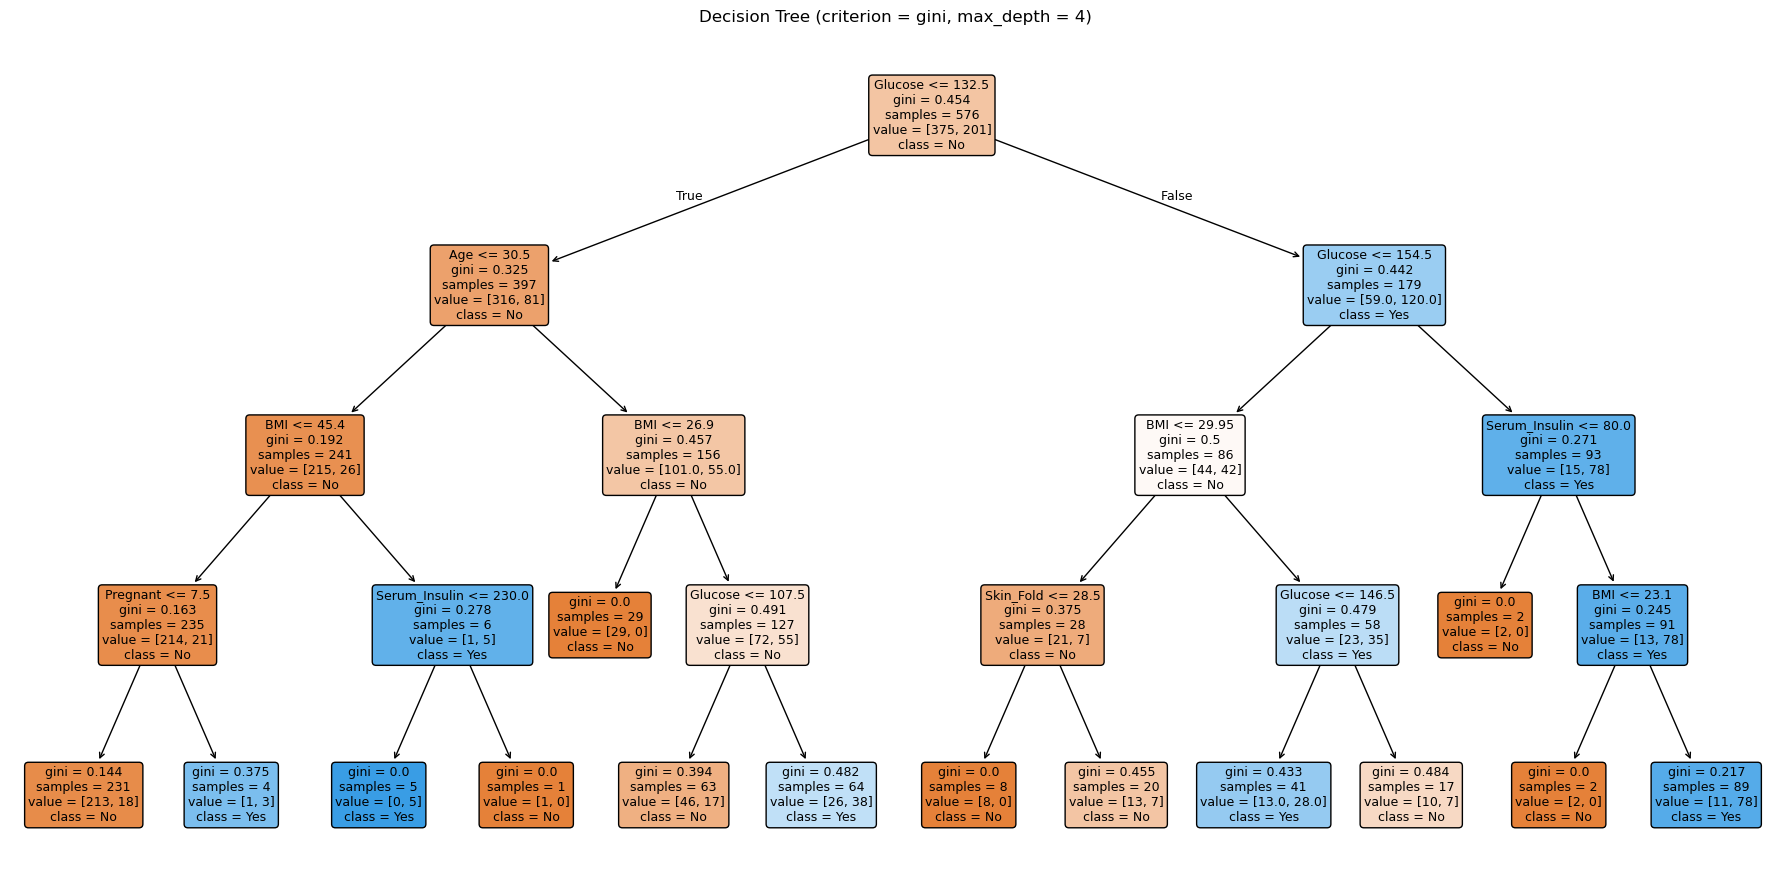

In [4]:
plt.figure(figsize=(18, 9))
plot_tree(dt, feature_names=X.columns, class_names=["No", "Yes"],
          filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (criterion = gini, max_depth = 4)")
plt.tight_layout()
plt.show()

## 4. Types of Decision Tree - Gini vs Entropy

The split **criterion** is the main "type" of a decision tree. We train one tree with each
criterion and compare them.

In [5]:
rows = []
for crit in ["gini", "entropy"]:
    m = DecisionTreeClassifier(criterion=crit, max_depth=4, random_state=42)
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({
        "Criterion": crit,
        "Accuracy":  accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall":    recall_score(y_test, p),
    })

crit_results = pd.DataFrame(rows)
crit_results.round(3)

,Criterion,Accuracy,Precision,Recall
0,gini,0.750,0.651,0.612
1,entropy,0.708,0.608,0.463


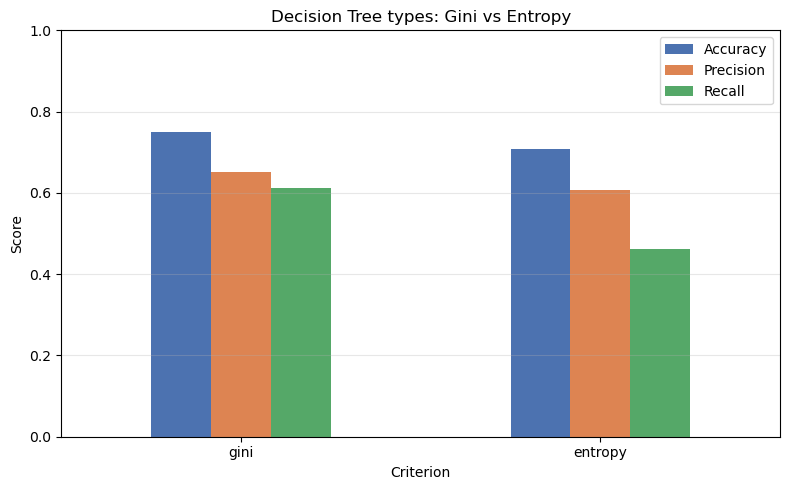

In [6]:
crit_results.set_index("Criterion").plot(kind="bar", figsize=(8, 5),
                                          color=["#4C72B0", "#DD8452", "#55A868"])
plt.title("Decision Tree types: Gini vs Entropy")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

## 5. Effect of tree depth (`max_depth`)

Grow the tree from depth 1 to 15 (criterion = gini) and watch the three metrics. Shallow trees
underfit; very deep trees overfit the training data.

In [7]:
depths = list(range(1, 16))
rows = []
for d in depths:
    m = DecisionTreeClassifier(criterion="gini", max_depth=d, random_state=42)
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({
        "max_depth": d,
        "Accuracy":  accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p),
        "Recall":    recall_score(y_test, p),
    })

depth_results = pd.DataFrame(rows)
depth_results.round(3)

,max_depth,Accuracy,Precision,Recall
0,1,0.682,0.548,0.507
1,2,0.708,0.690,0.299
2,3,0.708,0.608,0.463
3,4,0.750,0.651,0.612
4,5,0.750,0.646,0.627
5,6,0.750,0.651,0.612
6,7,0.766,0.677,0.627
7,8,0.750,0.646,0.627
8,9,0.724,0.630,0.507
9,10,0.745,0.661,0.552


### 5.1 Graph - metrics vs tree depth

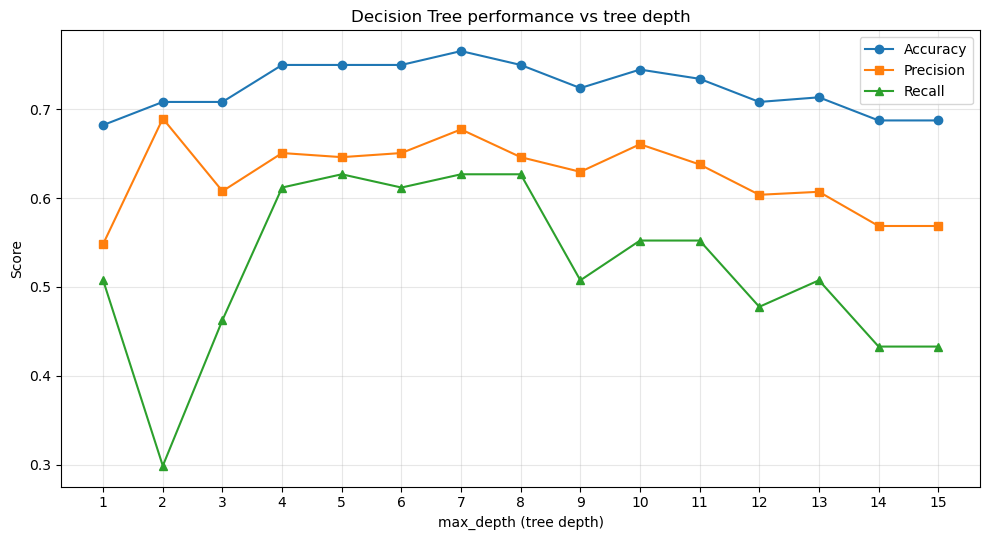

In [8]:
plt.figure(figsize=(10, 5.5))
plt.plot(depth_results["max_depth"], depth_results["Accuracy"],  marker="o", label="Accuracy")
plt.plot(depth_results["max_depth"], depth_results["Precision"], marker="s", label="Precision")
plt.plot(depth_results["max_depth"], depth_results["Recall"],    marker="^", label="Recall")
plt.xlabel("max_depth (tree depth)")
plt.ylabel("Score")
plt.title("Decision Tree performance vs tree depth")
plt.xticks(depths)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 5.2 Feature importance

Best depth by accuracy: 7


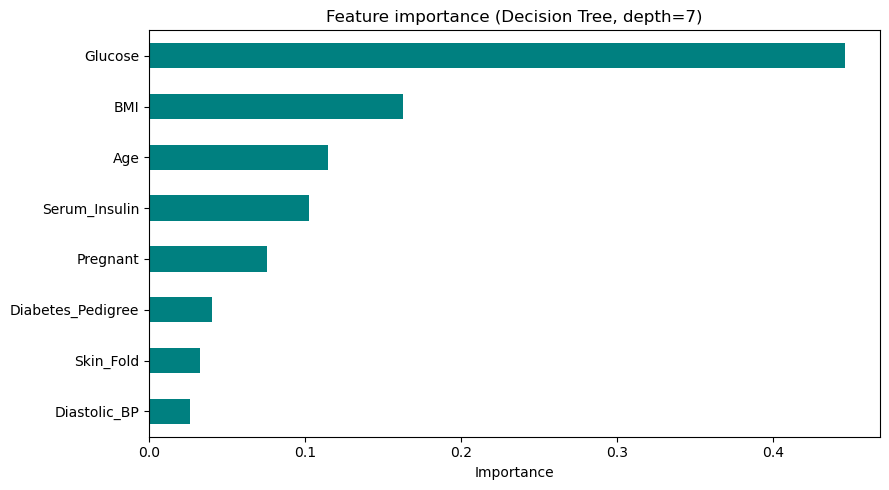

In [9]:
best_depth = int(depth_results.loc[depth_results["Accuracy"].idxmax(), "max_depth"])
best = DecisionTreeClassifier(criterion="gini", max_depth=best_depth, random_state=42)
best.fit(X_train, y_train)
print("Best depth by accuracy:", best_depth)

imp = pd.Series(best.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(9, 5))
imp.plot(kind="barh", color="teal")
plt.xlabel("Importance")
plt.title(f"Feature importance (Decision Tree, depth={best_depth})")
plt.tight_layout()
plt.show()